In [1]:
import pandas as pd

base = pd.read_csv("../data/processed/base_modelo.csv", parse_dates=["order_purchase_timestamp"])
base = base.sort_values("order_purchase_timestamp")

# Separação TEMPORAL: treina com o passado, testa com o "futuro" (últimos 20% dos pedidos)
corte = base["order_purchase_timestamp"].quantile(0.8)
treino = base[base["order_purchase_timestamp"] < corte]
teste  = base[base["order_purchase_timestamp"] >= corte]

print("data de corte:", corte.date())
print(f"treino: {len(treino)} pedidos | taxa negativa {treino['negativa'].mean():.1%}")
print(f"teste:  {len(teste)} pedidos | taxa negativa {teste['negativa'].mean():.1%}")

data de corte: 2018-05-27
treino: 76659 pedidos | taxa negativa 13.6%
teste:  19165 pedidos | taxa negativa 9.7%


In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, average_precision_score, roc_auc_score

categoricas = ["categoria", "estado_vendedor", "estado_cliente", "forma_pagamento"]
numericas = [c for c in base.columns if c not in categoricas + ["order_id", "order_purchase_timestamp", "negativa"]]

X_treino, y_treino = treino[numericas + categoricas], treino["negativa"]
X_teste,  y_teste  = teste[numericas + categoricas],  teste["negativa"]

# Preparação: preenche faltantes, padroniza números e transforma texto em colunas 0/1
preparacao = ColumnTransformer([
    ("num", Pipeline([("faltantes", SimpleImputer(strategy="median")),
                      ("escala", StandardScaler())]), numericas),
    ("cat", Pipeline([("faltantes", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=50))]), categoricas),
])

modelo_base = Pipeline([
    ("preparacao", preparacao),
    ("modelo", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

modelo_base.fit(X_treino, y_treino)
prob = modelo_base.predict_proba(X_teste)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_teste, prob), 3))
print("PR-AUC: ", round(average_precision_score(y_teste, prob), 3))
print(classification_report(y_teste, (prob >= 0.5).astype(int), digits=3))

ROC-AUC: 0.693
PR-AUC:  0.278
              precision    recall  f1-score   support

           0      0.929     0.921     0.925     17311
           1      0.318     0.343     0.330      1854

    accuracy                          0.865     19165
   macro avg      0.624     0.632     0.628     19165
weighted avg      0.870     0.865     0.868     19165



In [3]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

# Árvores só precisam que as categorias virem números (0, 1, 2...)
preparacao_arvore = ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                            encoded_missing_value=-1), categoricas)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

modelo_gb = Pipeline([
    ("preparacao", preparacao_arvore),
    ("modelo", HistGradientBoostingClassifier(
        categorical_features=[0, 1, 2, 3],   # as 4 primeiras colunas são as categóricas
        class_weight="balanced",
        max_iter=300,
        learning_rate=0.05,
        random_state=42,
    )),
])

modelo_gb.fit(X_treino, y_treino)
prob_gb = modelo_gb.predict_proba(X_teste)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_teste, prob_gb), 3))
print("PR-AUC: ", round(average_precision_score(y_teste, prob_gb), 3))
print(classification_report(y_teste, (prob_gb >= 0.5).astype(int), digits=3))

ROC-AUC: 0.699
PR-AUC:  0.318
              precision    recall  f1-score   support

           0      0.931     0.913     0.922     17311
           1      0.312     0.369     0.338      1854

    accuracy                          0.860     19165
   macro avg      0.622     0.641     0.630     19165
weighted avg      0.871     0.860     0.865     19165



In [4]:
import numpy as np

linhas = []
for corte_prob in [0.5, 0.6, 0.7, 0.8]:
    alerta = prob_gb >= corte_prob
    acertos = (alerta & (y_teste == 1)).sum()
    linhas.append({
        "corte": corte_prob,
        "pedidos_alertados": int(alerta.sum()),
        "precisao": round(acertos / alerta.sum(), 3),
        "recall": round(acertos / y_teste.sum(), 3),
    })
print(pd.DataFrame(linhas))

   corte  pedidos_alertados  precisao  recall
0    0.5               2196     0.312   0.369
1    0.6               1393     0.406   0.305
2    0.7                867     0.512   0.239
3    0.8                628     0.580   0.196


dias_atraso                0.1454
n_itens                    0.0655
n_vendedores               0.0141
dias_entrega               0.0125
categoria                  0.0067
estado_cliente             0.0064
dias_ate_transportadora    0.0039
horas_aprovacao            0.0031
dias_prometidos            0.0028
tam_descricao_media        0.0015
dtype: float64


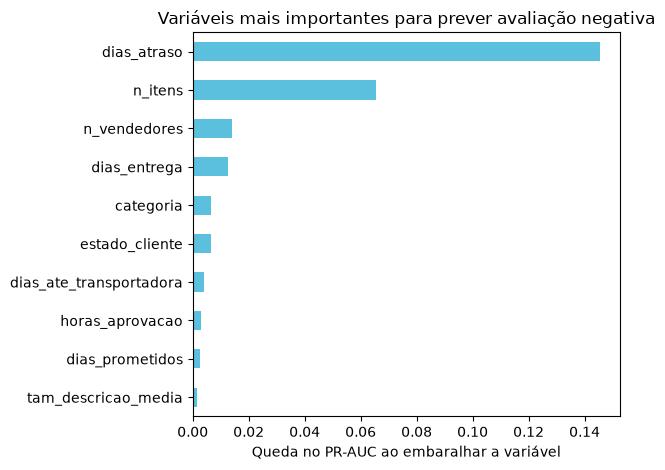

In [5]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt

resultado = permutation_importance(
    modelo_gb, X_teste, y_teste,
    scoring="average_precision",   # mede a piora no PR-AUC
    n_repeats=5, random_state=42, n_jobs=-1,
)

importancia = (pd.Series(resultado.importances_mean, index=X_teste.columns)
               .sort_values(ascending=False))
print(importancia.round(4).head(10))

# Gráfico das 10 mais importantes (vai para o README)
ax = importancia.head(10).sort_values().plot(kind="barh", color="#5bc0de")
ax.set_title("Variáveis mais importantes para prever avaliação negativa")
ax.set_xlabel("Queda no PR-AUC ao embaralhar a variável")
plt.tight_layout()
plt.savefig("../reports/figures/importancia_variaveis.png", dpi=120)
plt.show()

## Conclusões

**Desempenho (teste com os pedidos mais recentes):**

| Modelo | ROC-AUC | PR-AUC |
|---|---|---|
| Acaso (referência) | 0,50 | ~0,10 |
| Regressão logística | 0,69 | 0,28 |
| Gradient boosting | 0,70 | 0,32 |

- Com corte de probabilidade em 0,8, o modelo aponta ~630 pedidos e **58% deles realmente recebem avaliação negativa**, contra 9,7% de um sorteio aleatório: **~6x mais eficiente** para priorizar o atendimento.

**Fatores mais importantes:** atraso na entrega, número de itens, número de vendedores e tempo total de entrega.

**Hipótese x resultado:** eu esperava `dias_atraso`, `dias_entrega` e `n_vendedores`. O modelo confirmou atraso e vendedores, mas mostrou `n_itens` em 2º: mais itens significam mais chances de um deles dar problema, e isso afeta muito mais pedidos do que os de múltiplos vendedores.

**Limitações:** muitas avaliações negativas dependem de fatores que não estão na base (qualidade do produto, item diferente do anunciado, embalagem danificada). Por isso o desempenho é moderado, e o modelo deve ser usado para **priorizar** contatos, não como verdade absoluta.

**Recomendações ao negócio:**
1. Contatar proativamente os pedidos atrasados e os de maior risco segundo o modelo.
2. Em pedidos com vários itens ou vendedores, avisar que podem chegar em entregas separadas, ou só enviar a pesquisa de satisfação depois da última entrega.
3. Revisar prazos prometidos, já que o atraso é o fator mais forte.